In [1]:
%reload_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
from sentence_transformers import SentenceTransformer

from src.alentar_llm.data_load import get_cods_dict, clean_data
from src.alentar_llm.metrics import (calculate_mmd,
                                     get_top_ngrams, get_meteor, get_rouge,
                                     calculate_all_sms, calculate_self_bleu,
                                     lexical_diversity, calculate_nnd,
                                     get_plagiarism_candidates,
                                     get_bertscore, combine_embeddigs,
                                     get_tsne_embeddings , get_umap_embeddings,
                                     show_embeddings)

/root/micromamba/envs/alentar_llm_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [3]:
res_list = []

# Load real data 
df_real = pd.read_csv('Informes-Urgencias/EJEI_nocod_Clasificator_2024_07_ 04. 4.fin.csv')
cods = get_cods_dict('Informes-Urgencias/vars.csv')
df_real = clean_data(df_real, cods)

real_reports = df_real['EJEIDiagnóstico'].values
real_reports = [str(v) for v in real_reports]

# Get sentence embedding model
emb_model = SentenceTransformer('all-MiniLM-L6-v2')
emb_real = emb_model.encode(real_reports)

for model_name in ['deepseek-r1',
                   'openbiollm-llama3-70b.i1-q4_k_m.gguf',
                   'qwen3.5:35b-a3b-q8_0']:
    
    # Load synthetic model data
    df_da = pd.read_csv(f'llm_responses_{model_name}.csv', delimiter='|')
    df_da = df_da[df_da['response']!='ERROR']
    da_reports = df_da['response'].values
    da_reports = [str(v) for v in da_reports]
    emb_da = emb_model.encode(da_reports)
    
    row = {}
    row['Model_Name'] = model_name

    # Evaluate synthetic Data Augmentation
    row['MMD ▼'] = calculate_mmd(emb_real, emb_da)
    for key, value in get_rouge(real_reports, da_reports).items():
        row[key + ' ▼'] = value
    row['METEOR ▼'] = get_meteor(real_reports, da_reports)['meteor']
    row['Average_SMS ▼'] = np.mean(calculate_all_sms(real_reports, da_reports))
    row['Self_BLEU ▼'] = calculate_self_bleu(da_reports)
    row['TTR ▲'] = lexical_diversity(da_reports)
    avg_nnd, all_nnds = calculate_nnd(emb_real, emb_da)
    row['Average_NND ▲'] = avg_nnd
    row['Plagiarism_Percentage ▼'] = sum(all_nnds<0.05)/len(all_nnds)
    P, R, F1 = get_bertscore(real_reports, da_reports)
    row['Average_BERTScore_F1 ▲'] = F1.mean().item()
    
    res_list.append(row)

/tmp/ipykernel_863101/1444504781.py:4: DtypeWarning: Columns (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93) have mixed types. Specify dtype option on import or set low_memory=False.
  df_real = pd.read_csv('Informes-Urgencias/EJEI_nocod_Clasificator_2024_07_ 04. 4.fin.csv')
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4058.64it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!

In [4]:
df_results = pd.DataFrame(res_list)
df_results.set_index('Model_Name', inplace=True)
df_style = (df_results.style
            .highlight_min(
                subset=['MMD ▼', 'rouge1 ▼', 'rouge2 ▼', 'rougeL ▼',
                        'rougeLsum ▼', 'METEOR ▼', 'Average_SMS ▼',
                        'Self_BLEU ▼', 'Plagiarism_Percentage ▼'],
                props='font-weight: bold;')
            .highlight_max(
                subset=['TTR ▲', 'Average_BERTScore_F1 ▲', 'Average_NND ▲'],
                props='font-weight: bold;')
           )
df_style

,MMD ▼,rouge1 ▼,rouge2 ▼,rougeL ▼,rougeLsum ▼,METEOR ▼,Average_SMS ▼,Self_BLEU ▼,TTR ▲,Average_NND ▲,Plagiarism_Percentage ▼,Average_BERTScore_F1 ▲
Model_Name,,,,,,,,,,,,
deepseek-r1,0.012376,0.073577,0.004815,0.068043,0.067710,0.056328,0.513840,0.133861,0.985915,0.186267,0.059540,0.690498
openbiollm-llama3-70b.i1-q4_k_m.gguf,0.027490,0.063791,0.007150,0.058687,0.058422,0.040254,0.431018,0.233540,0.978298,0.203023,0.099057,0.685658
qwen3.5:35b-a3b-q8_0,0.014994,0.059311,0.003604,0.056909,0.056801,0.052828,0.499790,0.120151,0.991484,0.231693,0.023333,0.688578


In [5]:
df_results.to_csv('da_metrics.csv')

df_results = df_results.apply(
    lambda col: [f"\\textbf{{{v:.3f}}}" if v == col.max() else f"{v:.3f}" for v in col]
)
df_results.columns = [f"\\textbf{{{col}}}" for col in df_results.columns]

In [6]:
print(df_results.style.to_latex(
    caption="Synthetic text metrics for \texttt{deepseek-r1}, \texttt{openbiollm-llama3-70b.i1-q4\_k\_m.gguf} and \texttt{qwen3.5:35b-a3b-q8\_0}",
    label="tab:da_results",
    position="h!",
    hrules=True
))

\begin{table}[h!]
\caption{Synthetic text metrics for 	exttt{deepseek-r1}, 	exttt{openbiollm-llama3-70b.i1-q4\_k\_m.gguf} and 	exttt{qwen3.5:35b-a3b-q8\_0}}
\label{tab:da_results}
\begin{tabular}{lllllllllllll}
\toprule
 & \textbf{MMD ▼} & \textbf{rouge1 ▼} & \textbf{rouge2 ▼} & \textbf{rougeL ▼} & \textbf{rougeLsum ▼} & \textbf{METEOR ▼} & \textbf{Average_SMS ▼} & \textbf{Self_BLEU ▼} & \textbf{TTR ▲} & \textbf{Average_NND ▲} & \textbf{Plagiarism_Percentage ▼} & \textbf{Average_BERTScore_F1 ▲} \\
Model_Name &  &  &  &  &  &  &  &  &  &  &  &  \\
\midrule
deepseek-r1 & 0.012 & \textbf{0.074} & 0.005 & \textbf{0.068} & \textbf{0.068} & \textbf{0.056} & \textbf{0.514} & 0.134 & 0.986 & 0.186 & 0.060 & \textbf{0.690} \\
openbiollm-llama3-70b.i1-q4_k_m.gguf & \textbf{0.027} & 0.064 & \textbf{0.007} & 0.059 & 0.058 & 0.040 & 0.431 & \textbf{0.234} & 0.978 & 0.203 & \textbf{0.099} & 0.686 \\
qwen3.5:35b-a3b-q8_0 & 0.015 & 0.059 & 0.004 & 0.057 & 0.057 & 0.053 & 0.500 & 0.120 & \textbf{0.991}

<>:2: SyntaxWarning: invalid escape sequence '\_'
<>:2: SyntaxWarning: invalid escape sequence '\_'
/tmp/ipykernel_863101/1227240050.py:2: SyntaxWarning: invalid escape sequence '\_'
  caption="Synthetic text metrics for \texttt{deepseek-r1}, \texttt{openbiollm-llama3-70b.i1-q4\_k\_m.gguf} and \texttt{qwen3.5:35b-a3b-q8\_0}",


# Show embeddings

In [7]:
emb_model = SentenceTransformer('all-MiniLM-L6-v2')
df_real = pd.read_csv('Informes-Urgencias/EJEI_nocod_Clasificator_2024_07_ 04. 4.fin.csv')
real_reports = df_real['EJEIDiagnóstico'].values
real_reports = [str(v) for v in real_reports]
emb_real = emb_model.encode(real_reports)
emb_da_dict = {}
for model_name in ['deepseek-r1',
                   'openbiollm-llama3-70b.i1-q4_k_m.gguf',
                   'qwen3.5:35b-a3b-q8_0']:
    
    # Load synthetic model data
    df_da = pd.read_csv(f'llm_responses_{model_name}.csv', delimiter='|')
    df_da = df_da[df_da['response']!='ERROR']
    da_reports = df_da['response'].values
    da_reports = [str(v) for v in da_reports]
    emb_da_dict[model_name] = emb_model.encode(da_reports)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5181.20it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_863101/1457327696.py:2: DtypeWarning: Columns (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93) have mixed types. Specify dtype option on import or set low_memory=False.
  df_real = pd.read_csv('Informes-Urgencias/EJEI_nocod_Clasificator_2024_07_ 04. 4.fin.csv')


In [8]:
all_embeddings, labels = combine_embeddigs(emb_real, emb_da_dict)
embeddings_2d_tsne = get_tsne_embeddings(all_embeddings)
embeddings_2d_umap = get_umap_embeddings(all_embeddings)

/root/micromamba/envs/alentar_llm_env/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/root/micromamba/envs/alentar_llm_env/lib/python3.12/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/root/micromamba/envs/alentar_llm_env/lib/python3.12/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/root/micromamba/envs/alentar_llm_env/lib/python3.12/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to to

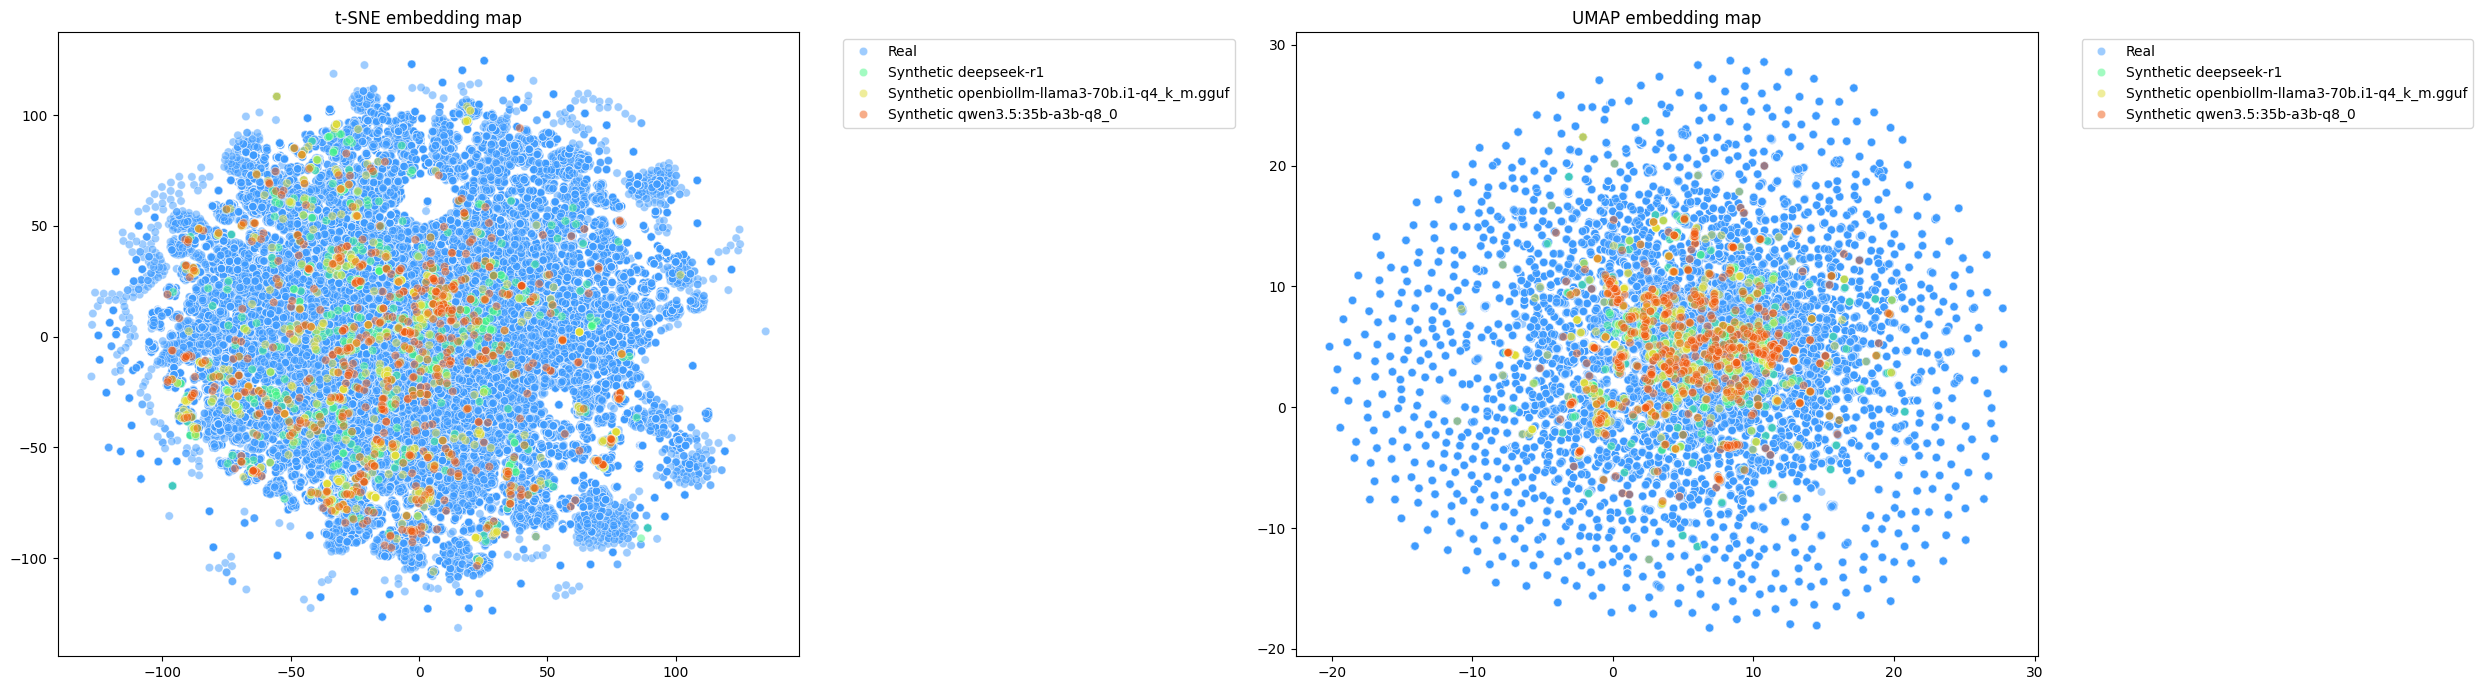

In [9]:
show_embeddings(embeddings_2d_tsne, embeddings_2d_umap, labels)

# Top similar n-grams

In [10]:
n = 2
top_real = get_top_ngrams(real_reports, n=n)
top_da = get_top_ngrams(da_reports, n=n)

print(f"Top Real {n}-grams:", top_real)
print(f"\nTop Synthetic {n}-grams:", top_da)

Top Real 2-grams: [('trastorno de', np.int64(9179)), ('de ansiedad', np.int64(6449)), ('deterioro cognitivo', np.int64(6046)), ('de personalidad', np.int64(5563)), ('trastorno adaptativo', np.int64(5415)), ('en remisión', np.int64(4941)), ('impresiona de', np.int64(4721)), ('trastorno depresivo', np.int64(4683)), ('de inicio', np.int64(4133)), ('de deterioro', np.int64(4088))]

Top Synthetic 2-grams: [('trastorno de', np.int64(29)), ('con síntomas', np.int64(22)), ('episodio depresivo', np.int64(21)), ('de personalidad', np.int64(19)), ('de la', np.int64(19)), ('trastorno depresivo', np.int64(17)), ('en contexto', np.int64(16)), ('trastorno del', np.int64(15)), ('síndrome de', np.int64(15)), ('con rasgos', np.int64(14))]


# Plagiarism detected

In [11]:
plagiarism_threshold = 0.05 
avg_nnd, all_nnds = calculate_nnd(emb_real, emb_da)
leaked = np.sum(all_nnds < plagiarism_threshold)
print(f"Reports with suspicion of plagiarism (<{plagiarism_threshold} dist): {leaked}")

df_suspicius = get_plagiarism_candidates(
    da_reports, 
    real_reports, 
    emb_da, 
    emb_real, 
    threshold=plagiarism_threshold
)

df_suspicius

Reports with suspicion of plagiarism (<0.05 dist): 20


,Synthetic_ID,NND,Synthetic report,Closest neighbor
3,60,0.0000,"Trastorno depresivo recurrente, episodio actua...","Trastorno depresivo recurrente, episodio actu..."
4,61,0.0000,"Trastorno depresivo recurrente, episodio actua...","Trastorno depresivo recurrente, episodio actu..."
6,63,0.0000,"Trastorno depresivo recurrente, episodio actua...","Trastorno depresivo recurrente, episodio actua..."
11,118,0.0000,Trastorno de pánico con agorafobia,Trastorno de pánico con agorafobia
10,112,0.0000,Agorafobia sin trastorno de pánico,Agorafobia sin trastorno de pánico
1,51,0.0055,Trastorno depresivo recurrente en remisión par...,"Trastorno depresivo recurrente, en remisión pa..."
5,62,0.0166,"Trastorno depresivo recurrente, episodio actua...","Trastorno depresivo, episodio actual grave sin..."
9,94,0.0186,Síndrome depresivo distímico crónico,Síndrome depresivo crónico
19,573,0.0267,Trastorno esquizoafectivo con síntomas psicóti...,trastorno esquizoafectivo con sintomas psicoticos
12,141,0.0273,Trastorno de ansiedad paroxística sin agorafobia,Trastorno de ansiedad paroxística. Agorafobia.
